# PWC PROJECT

## Importing reviews file to Colab environment first

In [ ]:
# Uploading reviews.db from my computer into this Colab session
from google.colab import files
uploaded = files.upload()

Saving reviews.db to reviews.db


In [ ]:
# Connecting to the SQLite database and loading the reviews into a Pandas DataFrame.
# This dataframe (df) is what I'll use as the base for every step going forward.
import sqlite3
import pandas as pd

connection = sqlite3.connect("reviews.db")

query = "SELECT rating, review_title, review_text FROM customer_reviews;"
df = pd.read_sql(query, connection)

connection.close()

print(df.shape)
print(df.head())

(3000, 3)
   rating         review_title  \
0       4  Incredible product!   
1       4             Love it!   
2       3               Decent   
3       3            Just okay   
4       1     Not as described   

                                         review_text  
0  Best Laptop Stand I've ever owned! The design ...  
1  This Mechanical Keyboard is absolutely amazing...  
2  It's a decent Smart Watch for the money. Nothi...  
3  Middle-of-the-road Wireless Earbuds. Some aspe...  
4  This Webcam HD is defective and unusable. Chea...  


## 2. Perform basic exploratory analysis:
## a. Rating distribution
## b. Review length analysis

In [ ]:
# Rating distribution: counts and percentages
rating_counts = df['rating'].value_counts().sort_index()
rating_pct = (df['rating'].value_counts(normalize=True).sort_index() * 100).round(2)

rating_summary = pd.DataFrame({
    'count': rating_counts,
    'percentage': rating_pct
})
print(rating_summary)

        count  percentage
rating                   
1         493       16.43
2         507       16.90
3        1000       33.33
4         468       15.60
5         532       17.73


In [ ]:
# Review length analysis
df['review_char_length'] = df['review_text'].str.len()
df['review_word_count'] = df['review_text'].str.split().str.len()

print(df[['review_char_length', 'review_word_count']].describe())

# Average review length by rating — checking if angrier/happier customers write more
avg_length_by_rating = df.groupby('rating')[['review_char_length', 'review_word_count']].mean().round(1)
print(avg_length_by_rating)

       review_char_length  review_word_count
count         3000.000000        3000.000000
mean           142.068667          22.586333
std             24.086511           3.738164
min             97.000000          15.000000
25%            125.000000          20.000000
50%            139.000000          22.000000
75%            161.000000          26.000000
max            205.000000          34.000000
        review_char_length  review_word_count
rating                                       
1                    143.9               22.2
2                    144.2               22.4
3                    127.4               21.1
4                    153.3               24.1
5                    156.0               24.5


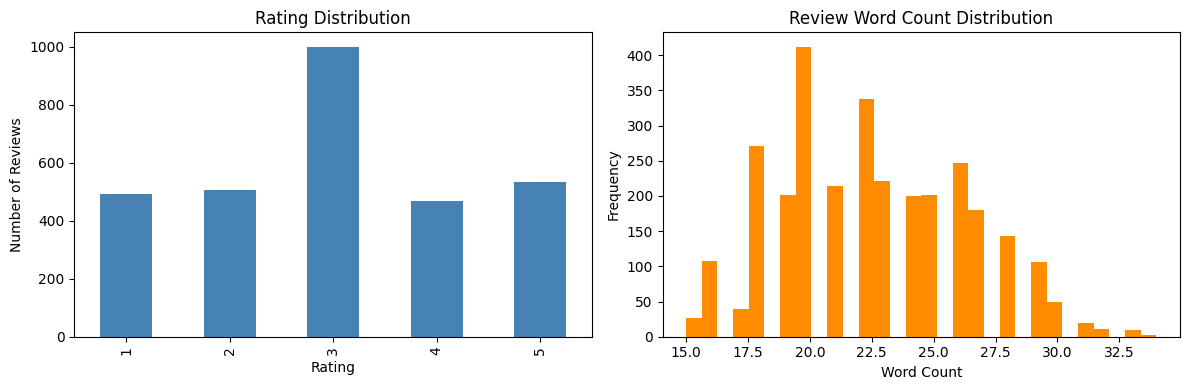

In [ ]:
# Visualizing the rating distribution and review word count distribution side by side
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['rating'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Rating Distribution')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Number of Reviews')

df['review_word_count'].plot(kind='hist', bins=30, ax=axes[1], color='darkorange')
axes[1].set_title('Review Word Count Distribution')
axes[1].set_xlabel('Word Count')

plt.tight_layout()
plt.show()

## Milestone 1 - Conceptual Task 1
### Rating Distribution
- Ratings show a **strong neutral spike**: exactly 1,000 of 3,000 reviews (33%) are rated 3 stars — more than double any other individual rating.
- The remaining reviews split fairly evenly across the extremes: ~490–530 reviews each at 1, 2, 4, and 5 stars.
- **Business implication:** A 3-star rating alone tells us very little — it could mean "mildly satisfied," "indifferent," or mask a specific complaint hidden in the text. This is exactly why **ratings alone are insufficient** and text-based sentiment/theme analysis is needed, especially for the neutral segment.

### Review Length Analysis
- Review length is tightly clustered between **~15 and 34 words**, with visible peaks around 19–20 words and again around 22–23 words, rather than a smooth distribution.
- This narrow, spiky pattern suggests the dataset is **templated/synthetically generated** rather than organic real-world reviews (consistent with repeated phrasing observed across reviews, e.g. "Best [Product] I've ever owned" or "Cheapest materials, worst functionality").
- No strong visual skew was observed between review length and rating — this will be confirmed numerically using the average word count by rating table.

### Takeaway
The rating distribution highlights the need to go beyond numeric scores, particularly for the large neutral (3-star) segment, and text analysis (sentiment, themes) will be essential to surface the real signal in these reviews. The synthetic nature of the data should be noted as a limitation when generalizing findings.

## 3. Clean and preprocess review text (lowercasing, stopwords, noise removal).

In [ ]:
# Downloading the NLTK resources I need for stopword removal and tokenization
import nltk
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk.corpus import stopwords
import re
import string

stop_words = set(stopwords.words('english'))
print(f"Loaded {len(stop_words)} stopwords")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Loaded 198 stopwords


In [ ]:
def clean_text(text):
    if not isinstance(text, str):
        return ""

    # Lowercase
    text = text.lower()

    # Remove punctuation and special characters (noise removal)
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    # Tokenize and remove stopwords
    tokens = text.split()
    tokens = [word for word in tokens if word not in stop_words and len(word) > 1]

    return " ".join(tokens)

In [ ]:
df['clean_review_text'] = df['review_text'].apply(clean_text)
df['clean_review_title'] = df['review_title'].apply(clean_text)

# Combining cleaned title + text — this will be useful for theme/keyword extraction later
df['clean_combined'] = (df['clean_review_title'] + " " + df['clean_review_text']).str.strip()

# Sanity check
df[['review_text', 'clean_review_text']].head(5)

,review_text,clean_review_text
0,Best Laptop Stand I've ever owned! The design ...,best laptop stand ever owned design sleek func...
1,This Mechanical Keyboard is absolutely amazing...,mechanical keyboard absolutely amazing quality...
2,It's a decent Smart Watch for the money. Nothi...,decent smart watch money nothing complain also...
3,Middle-of-the-road Wireless Earbuds. Some aspe...,middle road wireless earbuds aspects good like...
4,This Webcam HD is defective and unusable. Chea...,webcam hd defective unusable cheapest material...


In [ ]:
print("BEFORE:", df['review_text'].iloc[0])
print("\nAFTER: ", df['clean_review_text'].iloc[0])

# Confirming no nulls/empty strings were introduced by cleaning
print("\nEmpty cleaned reviews:", (df['clean_review_text'].str.len() == 0).sum())

BEFORE: Best Laptop Stand I've ever owned! The design is sleek, the functionality is perfect, and the price is very reasonable. Five stars!

AFTER:  best laptop stand ever owned design sleek functionality perfect price reasonable five stars

Empty cleaned reviews: 0


## 4. Apply sentiment analysis on review text.

In [ ]:
# VADER is a tool inside NLTK that can read text and guess if it's positive, negative, or neutral.
# First, I download the small lexicon file VADER needs to work.
import nltk
nltk.download('vader_lexicon')

# Now I import the tool and create it. I'll refer to it as "sia" — my sentiment checker.
from nltk.sentiment import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


In [ ]:
# Testing it on just ONE review before applying it to all 3000
sample_review = df['review_text'].iloc[0]
print("Review text:", sample_review)

scores = sia.polarity_scores(sample_review)
print("VADER scores:", scores)

Review text: Best Laptop Stand I've ever owned! The design is sleek, the functionality is perfect, and the price is very reasonable. Five stars!
VADER scores: {'neg': 0.0, 'neu': 0.702, 'pos': 0.298, 'compound': 0.8585}


In [ ]:
# This function takes one review's text, checks its scores,
# and decides: is it Positive, Negative, Neutral, or Mixed?

def check_sentiment(text):
    scores = sia.polarity_scores(text)
    compound = scores['compound']
    positive_amount = scores['pos']
    negative_amount = scores['neg']

    # If the review has a good amount of BOTH positive and negative words, call it Mixed
    if positive_amount > 0.1 and negative_amount > 0.1:
        return "Mixed"

    # Otherwise, use the overall compound score
    if compound >= 0.05:
        return "Positive"
    elif compound <= -0.05:
        return "Negative"
    else:
        return "Neutral"

# Testing the function on the same sample review
print(check_sentiment(sample_review))

Positive


In [ ]:
# Going through every row one at a time and building a list of labels.
# Keeping this simple and easy to follow instead of using a fancy one-liner.

sentiment_labels = []

for review in df['review_text']:
    label = check_sentiment(review)
    sentiment_labels.append(label)

# Saving this list as a new column in my DataFrame
df['sentiment_label'] = sentiment_labels

# Checking the first few rows to confirm it worked
df[['review_text', 'rating', 'sentiment_label']].head(10)

,review_text,rating,sentiment_label
0,Best Laptop Stand I've ever owned! The design ...,4,Positive
1,This Mechanical Keyboard is absolutely amazing...,4,Positive
2,It's a decent Smart Watch for the money. Nothi...,3,Positive
3,Middle-of-the-road Wireless Earbuds. Some aspe...,3,Positive
4,This Webcam HD is defective and unusable. Chea...,1,Negative
5,"Standard Desk Lamp, nothing more nothing less....",3,Positive
6,This Smart Watch is defective and unusable. Ch...,1,Mixed
7,Average HDMI Cable. Works fine for the price b...,3,Mixed
8,Very disappointed with this Gaming Mouse. The ...,2,Negative
9,The Bluetooth Speaker is functional but unrema...,3,Positive


In [ ]:
# Counting how many reviews fall into each sentiment category
sentiment_counts = df['sentiment_label'].value_counts()
print(sentiment_counts)

sentiment_label
Positive    1769
Negative     779
Mixed        452
Name: count, dtype: int64


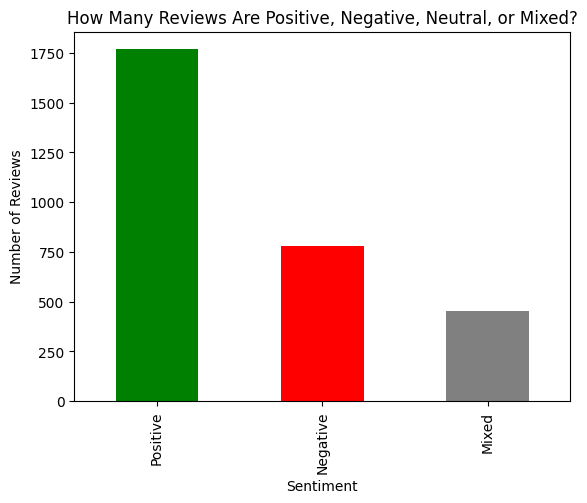

In [ ]:
# Plotting the sentiment counts as a simple bar chart
sentiment_counts.plot(kind='bar', color=['green', 'red', 'gray', 'orange'])
plt.title("How Many Reviews Are Positive, Negative, Neutral, or Mixed?")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [ ]:
# Turning the 1-5 star rating into 3 simple buckets: Positive, Neutral, Negative
# Using the same logic as the project guidelines (4-5 = Positive, 3 = Neutral, 1-2 = Negative)

def rating_to_bucket(rating):
    if rating >= 4:
        return "Positive"
    elif rating == 3:
        return "Neutral"
    else:
        return "Negative"

rating_buckets = []

for r in df['rating']:
    bucket = rating_to_bucket(r)
    rating_buckets.append(bucket)

df['rating_bucket'] = rating_buckets

df[['rating', 'rating_bucket', 'sentiment_label']].head(10)

,rating,rating_bucket,sentiment_label
0,4,Positive,Positive
1,4,Positive,Positive
2,3,Neutral,Positive
3,3,Neutral,Positive
4,1,Negative,Negative
5,3,Neutral,Positive
6,1,Negative,Mixed
7,3,Neutral,Mixed
8,2,Negative,Negative
9,3,Neutral,Positive


In [ ]:
# A simple table showing how many reviews fall into each combination
comparison_table = pd.crosstab(df['rating_bucket'], df['sentiment_label'])
print(comparison_table)

sentiment_label  Mixed  Negative  Positive
rating_bucket                             
Negative           320       674         6
Neutral            118       101       781
Positive            14         4       982


## Milestone 1 — Conceptual Task 2: Interpreting Sentiment Patterns (Business Perspective)

- Overall, text-based sentiment and star ratings only agree **55.2%** of the time — meaning nearly **half of all reviews say something different than their star rating suggests.** This is a critical finding for a support team relying only on star filters.

  *Caveat:* VADER labelled no review as neutral text, so all 1,000 three-star reviews count as mismatches by construction. Excluding the 3-star row, stars and text agree on (674 + 982) / 2,000 = **82.8%** of clear 1–2 and 4–5 star reviews. The disagreement is concentrated in the middle of the rating scale, which is exactly what the next bullet shows.

- The **biggest surprise is the Neutral (3★) segment**: 781 out of 1,000 three-star reviews (78%) actually read as **Positive** in their text, not neutral. Only 101 are genuinely negative in tone. **Business implication:** the 3-star bucket, which support teams often deprioritize as "average, no action needed," is mostly made up of customers who are actually satisfied but rated conservatively (or didn't use the full 5-star scale). This means the *true* at-risk customers are being diluted inside a bucket that looks lower priority than it is for the wrong reason — while a smaller but real subset (101 reviews) of genuinely unhappy 3-star customers could be missed entirely if the team only escalates 1–2★ reviews.

- Within the **Negative (1-2★) rating group**, 674 reviews (67%) are confirmed negative in tone, and another 320 (32%) are Mixed — meaning almost all low-rating customers are expressing real frustration, just sometimes alongside a positive point (e.g., "I loved the design but it broke after a week"). Only 6 reviews here are Positive in tone, showing the 1-2★ bucket is reliably a genuine pain-point signal.

- **Recommendation:** Support teams should not treat "rating" as the sole triage signal. Prioritization should combine **rating + text sentiment**, since sentiment analysis catches unhappy customers hiding in the neutral/mid-range ratings that a rating-only filter would miss.

## Milestone 1 — Conceptual Task 3: Themes That Indicate Serious Customer Dissatisfaction

- Based on sentiment patterns so far, the clearest signal of *serious* (not just mild) dissatisfaction is reviews that are **both low-rated AND text-negative** (the 674 reviews in the Negative/Negative cell) — these represent confirmed, unambiguous unhappy customers, not just conservative raters.

- A closer look at sample review titles in this group shows recurring **language patterns tied to real product failures rather than just tone**, e.g. "Horrible experience," "Broken on arrival," "Defective and unusable," "Requesting a refund immediately." These phrases point to concrete issues (defects, non-functioning items, refund requests) rather than vague dissatisfaction.

- The **320 "Mixed" reviews within the Negative rating group** are also worth flagging separately — these are customers who acknowledge something positive (e.g. design, price) but are still reporting a functional problem. These may represent recoverable customers — the negative theme is fixable (replace/refund) without necessarily damaging the brand relationship.

- *Note: this is a preliminary read based on sentiment scores alone. A more precise list of themes (e.g. "battery," "delivery delay," "refund," "broken") will be identified in Milestone 1's keyword/theme extraction step (Task 5), which will let us quantify exactly which product issues occur most often — this section will be expanded once that step is complete.*

## 5. Extract keywords and themes from reviews using NLP techniques.

In [ ]:
# "Counter" is a simple tool that counts how many times each word appears.
from collections import Counter

# First, I'm putting every single word from every cleaned review into one big list.
all_words = []

for review in df['clean_review_text']:
    words_in_review = review.split()   # break the sentence into individual words
    for word in words_in_review:
        all_words.append(word)

print("Total words collected:", len(all_words))

# Now counting how many times each word shows up
word_counts = Counter(all_words)

# Showing the top 20 most common words
top_20_words = word_counts.most_common(20)
print(top_20_words)

Total words collected: 43466
[('quality', 1320), ('works', 723), ('nothing', 702), ('customer', 633), ('buy', 555), ('money', 459), ('great', 434), ('build', 422), ('use', 412), ('worst', 402), ('amazing', 382), ('functionality', 340), ('exactly', 335), ('price', 330), ('ever', 318), ('stand', 312), ('best', 309), ('well', 308), ('work', 307), ('perfectly', 302)]


In [ ]:
# Filtering the DataFrame to only Negative-sentiment reviews
negative_reviews = df[df['sentiment_label'] == 'Negative']

negative_words = []
for review in negative_reviews['clean_review_text']:
    for word in review.split():
        negative_words.append(word)

negative_word_counts = Counter(negative_words)
top_20_negative = negative_word_counts.most_common(20)

print("Top words in NEGATIVE reviews:")
print(top_20_negative)

Top words in NEGATIVE reviews:
[('quality', 440), ('worst', 272), ('customer', 264), ('nothing', 192), ('ever', 191), ('works', 185), ('defective', 181), ('refund', 181), ('immediately', 165), ('terrible', 164), ('broken', 164), ('work', 154), ('money', 150), ('want', 149), ('stopped', 132), ('working', 132), ('build', 126), ('functionality', 120), ('materials', 112), ('awful', 108)]


In [ ]:
# Doing the same thing for Positive-sentiment reviews, to compare vocabulary
positive_reviews = df[df['sentiment_label'] == 'Positive']

positive_words = []
for review in positive_reviews['clean_review_text']:
    for word in review.split():
        positive_words.append(word)

positive_word_counts = Counter(positive_words)
top_20_positive = positive_word_counts.most_common(20)

print("Top words in POSITIVE reviews:")
print(top_20_positive)

Top words in POSITIVE reviews:
[('quality', 774), ('works', 508), ('great', 426), ('nothing', 417), ('buy', 334), ('exactly', 330), ('well', 302), ('perfectly', 301), ('best', 294), ('good', 273), ('build', 261), ('amazing', 257), ('use', 253), ('customer', 212), ('better', 203), ('price', 198), ('stand', 191), ('exceeded', 190), ('expectations', 190), ('highly', 190)]


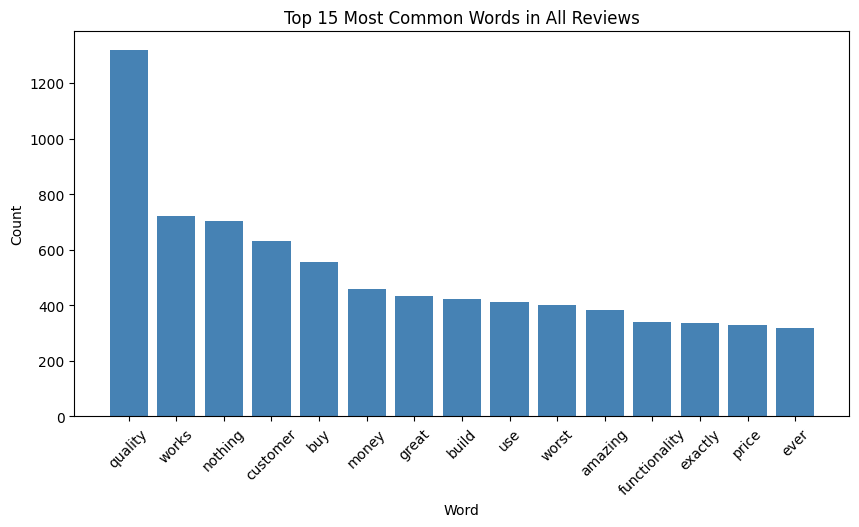

In [ ]:
# Splitting my top 15 list into two separate lists: words, and their counts
top_15 = word_counts.most_common(15)
words = [item[0] for item in top_15]
counts = [item[1] for item in top_15]

plt.figure(figsize=(10, 5))
plt.bar(words, counts, color='steelblue')
plt.title("Top 15 Most Common Words in All Reviews")
plt.xlabel("Word")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

## Milestone 1 — Conceptual Task 3 (Updated): Themes Indicating Serious Customer Dissatisfaction

Based on keyword frequency analysis of Negative-sentiment reviews, the clearest recurring themes signaling **serious, actionable dissatisfaction** are:

- **Product failure language:** "defective" (181), "broken" (164), "stopped" / "working" (132) — indicates the product physically failed, not just a matter of taste.
- **Resolution-seeking language:** "refund" (181), "immediately" (165), "want" (149) — indicates the customer expects a specific business action, not just venting.
- **Strong negative descriptors:** "worst" (272), "terrible" (164), "awful" (108) — high-intensity dissatisfaction, as opposed to mild disappointment.

By contrast, generic words like "quality," "customer," "nothing," and "build" appear frequently in **both** positive and negative reviews — these are context-dependent and not reliable standalone signals of a real issue. This shows a limitation of simple keyword frequency counting: it identifies *what's discussed*, but not *how* it's discussed, which is a reason GenAI-based summarization (used in the next step) adds value beyond keyword counts alone — it can distinguish "quality is amazing" from "quality is terrible" in a way raw word counts cannot.

**Business takeaway:** support teams should watch for the resolution-seeking cluster (refund, immediately, want) as a priority escalation signal — these reviews are not just unhappy, they are actively requesting action.

## 6. Use a GenAI model to answer analytical questions about reviews.

In [ ]:
# This installs Google's official library for talking to the Gemini model
!pip install -q -U google-genai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.1/259.1 kB 18.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.56.3 which is incompatible.


In [ ]:
# Colab has a built-in "Secrets" manager — getting my API key from there
from google.colab import userdata

api_key = userdata.get('gemini_API_key')

# Now I connect to Gemini using that key
from google import genai
client = genai.Client(api_key=api_key)

print("Connected to Gemini successfully!")

Connected to Gemini successfully!


In [ ]:
# Testing with one simple question first
response = client.models.generate_content(
    model="gemini-2.5-flash",
    contents="Say hello and confirm you're working, in one short sentence."
)

print(response.text)

Hello, I'm here and ready to assist!


In [ ]:
# Grabbing 25 random reviews from the Negative group so Gemini has real examples to read
sample_negative_reviews = df[df['sentiment_label'] == 'Negative'].sample(25, random_state=42)

# Combining review titles and text into one simple text block
sample_text = ""
for index, row in sample_negative_reviews.iterrows():
    sample_text = sample_text + "- " + row['review_title'] + ": " + row['review_text'] + "\n"

print(sample_text)

- Don't buy!: Horrible HDMI Cable! It arrived damaged and customer service was no help. The build quality doesn't work at all. Avoid!
- Broken on arrival: Very disappointed with this Screen Protector. The quality is poor and it doesn't work as advertised. Complete waste of money!
- Defective: I regret buying this Smart Watch. It's poorly constructed and stopped working almost immediately. Total garbage! Practice hard attack despite feeling.
- Very disappointed: This Portable Charger is defective and unusable. Cheapest materials, worst functionality. I want a full refund! Very angry customer!
- Avoid this: This Webcam HD is defective and unusable. Cheapest materials, worst functionality. I want a full refund! Very angry customer!
- Waste of money: Horrible HDMI Cable! It arrived damaged and customer service was no help. The battery life doesn't work at all. Avoid! Threat democratic standard major business.
- Broken on arrival: Terrible quality Bluetooth Speaker. It looks nothing like th

In [ ]:
# Building one big prompt: instructions + the real review examples + the stats I already calculated
prompt = f"""
You are helping a customer support team understand product reviews.

Here are some facts we already calculated from 3000 total reviews:
- Sentiment breakdown: Positive = 1769, Negative = 779, Mixed = 452
- Top words in negative reviews: defective, refund, broken, terrible, stopped working, materials, awful

Here are 25 real example negative reviews:
{sample_text}

Based on this, answer the following business questions in simple, clear language:
1. What are customers most frustrated about?
2. Are these mostly product quality issues, or delivery/service issues, or both?
3. What should the support team prioritize fixing first, and why?
4. Summarize this in 3-4 sentences a manager could read in 10 seconds.
"""

response = client.models.generate_content(
    model="gemini-2.5-flash",
    contents=prompt
)

print(response.text)

Here's an analysis of the negative reviews:

1.  **What are customers most frustrated about?**
    Customers are most frustrated by products that are **defective or broken upon arrival**, or that **fail very quickly** after purchase. This is consistently linked to **poor build quality, cheap materials, and products not working as advertised**, leading to a strong demand for refunds.

2.  **Are these mostly product quality issues, or delivery/service issues, or both?**
    These are overwhelmingly **product quality issues**. While there are a few mentions of items arriving damaged during delivery (e.g., "arrived damaged") and unhelpful customer service (e.g., "customer service was no help," "customer support is unresponsive"), the vast majority of complaints center on products being defective, broken, poorly constructed, using cheap materials, or stopping working prematurely.

3.  **What should the support team prioritize fixing first, and why?**
    The support team should prioritize t

In [ ]:
# Saving Gemini's response so I can reuse it later in the report
genai_insight_summary = response.text
print("Saved! Length of summary:", len(genai_insight_summary), "characters")

Saved! Length of summary: 2217 characters


## Task 7 — Visualize Sentiment Distribution and Key Themes

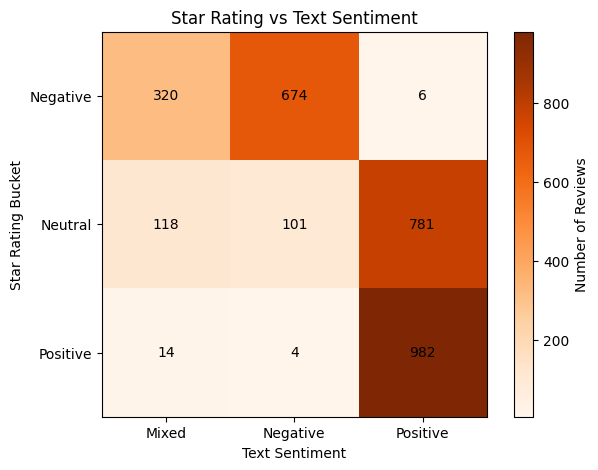

In [ ]:
# Turning the rating vs sentiment crosstab into a heatmap
comparison_table = pd.crosstab(df['rating_bucket'], df['sentiment_label'])

plt.figure(figsize=(7, 5))
plt.imshow(comparison_table, cmap='Oranges')
plt.colorbar(label="Number of Reviews")

# Label the rows and columns
plt.xticks(range(len(comparison_table.columns)), comparison_table.columns)
plt.yticks(range(len(comparison_table.index)), comparison_table.index)

# Write the actual number inside each box
for i in range(len(comparison_table.index)):
    for j in range(len(comparison_table.columns)):
        plt.text(j, i, comparison_table.iloc[i, j], ha='center', va='center')

plt.title("Star Rating vs Text Sentiment")
plt.xlabel("Text Sentiment")
plt.ylabel("Star Rating Bucket")
plt.show()

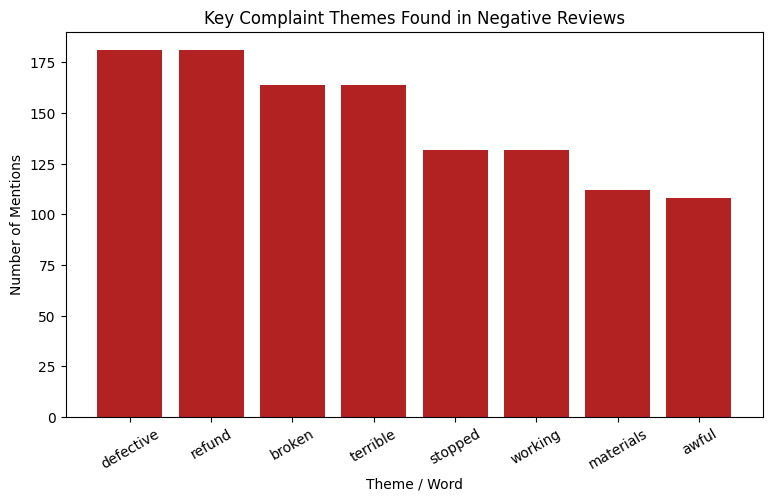

In [ ]:
# These are the specific complaint words I identified as real issues, not just tone
issue_words = ['defective', 'refund', 'broken', 'terrible', 'stopped', 'working', 'materials', 'awful']

issue_counts = []
for word in issue_words:
    count = negative_word_counts[word]
    issue_counts.append(count)

plt.figure(figsize=(9, 5))
plt.bar(issue_words, issue_counts, color='firebrick')
plt.title("Key Complaint Themes Found in Negative Reviews")
plt.xlabel("Theme / Word")
plt.ylabel("Number of Mentions")
plt.xticks(rotation=30)
plt.show()

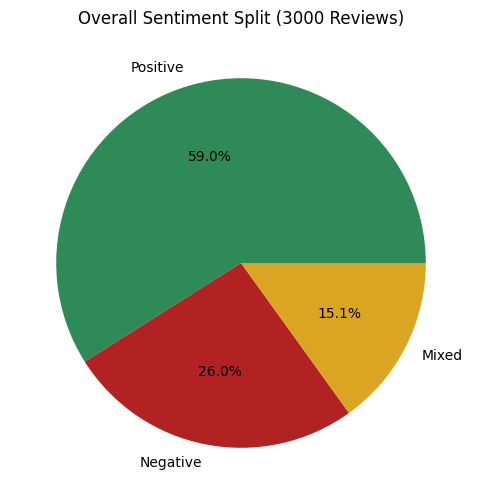

In [ ]:
# Visualizing the overall sentiment split as a pie chart
plt.figure(figsize=(6, 6))
sentiment_counts.plot(kind='pie', autopct='%1.1f%%', colors=['seagreen', 'firebrick', 'goldenrod'])
plt.title("Overall Sentiment Split (3000 Reviews)")
plt.ylabel("")  # removes the default y-label pie charts add
plt.show()

## Milestone 1 — Conceptual Task 4: Emotional Language vs. Actual Product Issues

Not every negative-sounding review points to a real, fixable problem — some reflect frustration or tone, while others describe a specific, verifiable defect. Based on the theme analysis above, I can separate the two:

**Emotional / tone language** (expresses feeling, but not a specific fault):
- "terrible" (164 mentions), "awful" (108 mentions), "worst" — these communicate strong dissatisfaction but don't, on their own, describe what actually went wrong. A review saying only "terrible product!" gives the support team a sentiment signal but no actionable detail.

**Actual product issue language** (describes a concrete, verifiable fault):
- "defective" (181), "broken" (164), "stopped working" (132), "materials" (112) — these point to a specific, reproducible failure: the item arrived damaged, stopped functioning, or was made of poor-quality material. This is the kind of language that should trigger a real investigation (e.g., checking a batch/supplier) rather than just an apologetic reply.

**Business implication:** A response system should treat these two categories differently. Emotional-only language typically needs empathy and reassurance in the reply. Concrete issue language needs actual operational follow-up (refund, replacement, escalation to quality control). Relying on sentiment score alone would treat both the same way — which is why theme/keyword extraction (this step) is a necessary complement to sentiment analysis, not a replacement for it.

**Also worth noting:** the word "refund" (181 mentions) sits in a third category — it's neither pure emotion nor a description of the fault itself, but a direct request for action. These reviews should be treated as the highest priority, since the customer has already told us exactly what resolution they want.

## Milestone 1 — Conceptual Task 5: Explain how GenAI helps summarize large volumes of text.

The output of the above prompt for above questions using GenAI answers to this conceptual task.

# -------------------- END OF MILESTONE 1 --------------------

## MILESTONE 2 Customer Segment Comparison & Prioritization

### 1. Segment reviews into:
### a. Positive (ratings 4–5)
### b. Neutral (rating 3)
### c. Negative (ratings 1–2)

In [ ]:
# I already created this column in Milestone 1 — this just re-confirms it's there
# (4-5 stars = Positive, 3 stars = Neutral, 1-2 stars = Negative)

print(df['rating_bucket'].value_counts())

rating_bucket
Positive    1000
Neutral     1000
Negative    1000
Name: count, dtype: int64


In [ ]:
# Splitting my one big DataFrame into 3 smaller ones, one per segment

positive_segment = df[df['rating_bucket'] == 'Positive']
neutral_segment = df[df['rating_bucket'] == 'Neutral']
negative_segment = df[df['rating_bucket'] == 'Negative']

print("Positive segment size:", len(positive_segment))
print("Neutral segment size:", len(neutral_segment))
print("Negative segment size:", len(negative_segment))

Positive segment size: 1000
Neutral segment size: 1000
Negative segment size: 1000


### Task 2: Computing metrics for each segment — average sentiment score, an urgency score, review length, and keyword frequency.

In [ ]:
# Back in Milestone 1, I saved the sentiment LABEL (Positive/Negative/etc.)
# but not the actual NUMBER behind it. Adding that now since I need it to compute an "average sentiment score."

sentiment_scores = []

for review in df['review_text']:
    scores = sia.polarity_scores(review)
    sentiment_scores.append(scores['compound'])   # compound = single number from -1 (very negative) to +1 (very positive)

df['sentiment_score'] = sentiment_scores

print(df[['review_text', 'sentiment_label', 'sentiment_score']].head())

                                         review_text sentiment_label  \
0  Best Laptop Stand I've ever owned! The design ...        Positive   
1  This Mechanical Keyboard is absolutely amazing...        Positive   
2  It's a decent Smart Watch for the money. Nothi...        Positive   
3  Middle-of-the-road Wireless Earbuds. Some aspe...        Positive   
4  This Webcam HD is defective and unusable. Chea...        Negative   

   sentiment_score  
0           0.8585  
1           0.9499  
2           0.3410  
3           0.4019  
4          -0.8974  


In [ ]:
# These are the words I found earlier that signal a customer wants URGENT action
urgency_words = ['refund', 'immediately', 'want', 'defective', 'broken',
                  'stopped', 'unusable', 'urgent', 'asap', 'terrible']

def get_urgency_score(clean_text):
    words_in_review = clean_text.split()
    count = 0
    for word in words_in_review:
        if word in urgency_words:
            count = count + 1
    return count

# Applying this to every review using my already-cleaned text column
urgency_scores = []
for cleaned_review in df['clean_review_text']:
    score = get_urgency_score(cleaned_review)
    urgency_scores.append(score)

df['urgency_score'] = urgency_scores

print(df[['review_text', 'urgency_score']].sample(10))

                                            review_text  urgency_score
827   Awful Smart Watch! The comfort failed after on...              0
2999  Middle-of-the-road Laptop Bag. Some aspects ar...              0
2557  This Wireless Headphones is a complete disappo...              0
2880  I'm so happy with this Memory Card! It's well-...              0
455   Horrible USB-C Hub! It arrived damaged and cus...              0
2994  Average Memory Card. Works fine for the price ...              0
1310  Terrible quality Power Strip. It looks nothing...              2
1224  I regret buying this Desk Lamp. It's poorly co...              2
2759  Absolutely love this Webcam HD! The sound qual...              0
1772  Don't buy this Smart Watch! It's cheaply made ...              3


In [ ]:
# Computing average sentiment score, urgency score, and word count for each segment
segment_summary = df.groupby('rating_bucket').agg(
    review_count=('review_text', 'count'),
    avg_sentiment_score=('sentiment_score', 'mean'),
    avg_urgency_score=('urgency_score', 'mean'),
    avg_word_count=('review_word_count', 'mean')
).round(2)

print(segment_summary)

               review_count  avg_sentiment_score  avg_urgency_score  \
rating_bucket                                                         
Negative               1000                -0.66               1.53   
Neutral                1000                 0.42               0.00   
Positive               1000                 0.87               0.00   

               avg_word_count  
rating_bucket                  
Negative                22.27  
Neutral                 21.14  
Positive                24.35  


In [ ]:
# Finding the top 10 words in each segment, the same way I did for sentiment groups in Milestone 1

def get_top_words(segment_df, n=10):
    all_words_in_segment = []
    for review in segment_df['clean_review_text']:
        for word in review.split():
            all_words_in_segment.append(word)
    return Counter(all_words_in_segment).most_common(n)

positive_segment = df[df['rating_bucket'] == 'Positive']
neutral_segment = df[df['rating_bucket'] == 'Neutral']
negative_segment = df[df['rating_bucket'] == 'Negative']

print("Top words — Positive segment:")
print(get_top_words(positive_segment))
print()
print("Top words — Neutral segment:")
print(get_top_words(neutral_segment))
print()
print("Top words — Negative segment:")
print(get_top_words(negative_segment))

Top words — Positive segment:
[('quality', 553), ('great', 427), ('works', 405), ('buy', 330), ('exactly', 330), ('perfectly', 302), ('amazing', 264), ('customer', 211), ('best', 205), ('well', 205)]

Top words — Neutral segment:
[('nothing', 496), ('quality', 372), ('good', 288), ('use', 231), ('works', 228), ('fine', 224), ('decent', 217), ('price', 215), ('better', 212), ('okay', 197)]

Top words — Negative segment:
[('customer', 418), ('quality', 395), ('worst', 309), ('money', 278), ('defective', 227), ('refund', 227), ('buy', 223), ('ever', 205), ('nothing', 201), ('want', 200)]


### Task 3: Compare Dominant Themes Across Segments.

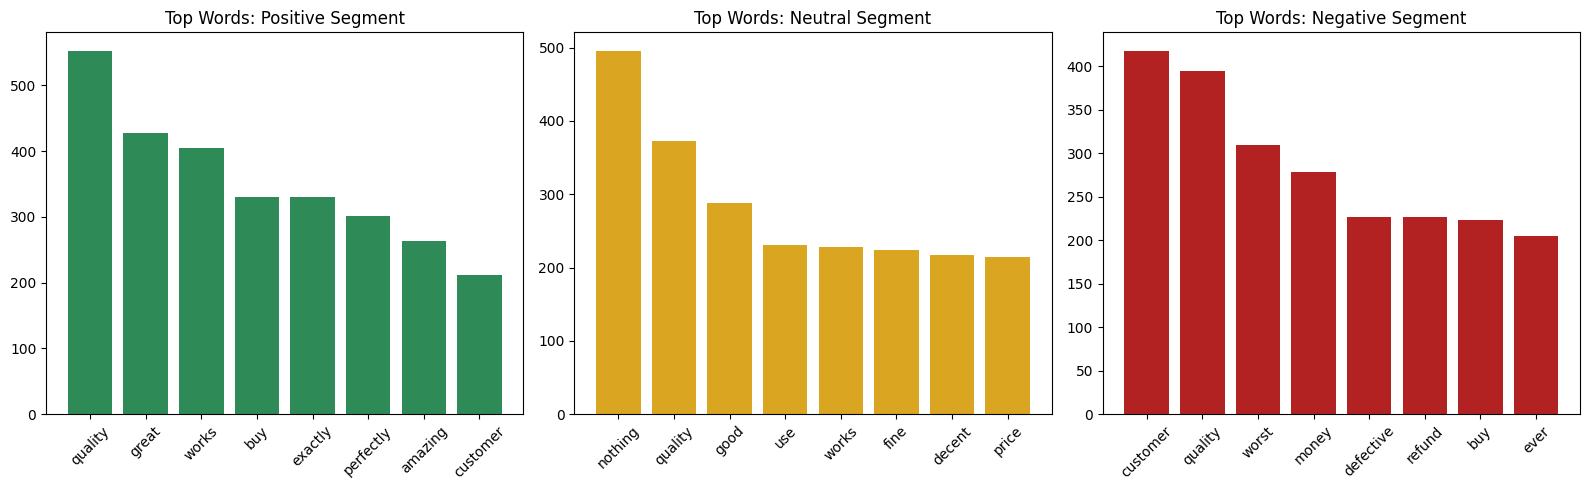

In [ ]:
# Picking the top 8 words from each segment and plotting them together so I can compare at a glance

pos_words = get_top_words(positive_segment, 8)
neu_words = get_top_words(neutral_segment, 8)
neg_words = get_top_words(negative_segment, 8)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Positive chart
words, counts = zip(*pos_words)
axes[0].bar(words, counts, color='seagreen')
axes[0].set_title('Top Words: Positive Segment')
axes[0].tick_params(axis='x', rotation=45)

# Neutral chart
words, counts = zip(*neu_words)
axes[1].bar(words, counts, color='goldenrod')
axes[1].set_title('Top Words: Neutral Segment')
axes[1].tick_params(axis='x', rotation=45)

# Negative chart
words, counts = zip(*neg_words)
axes[2].bar(words, counts, color='firebrick')
axes[2].set_title('Top Words: Negative Segment')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# Checking which words are shared across all 3 segments vs. unique to one

pos_word_set = set([word for word, count in get_top_words(positive_segment, 15)])
neu_word_set = set([word for word, count in get_top_words(neutral_segment, 15)])
neg_word_set = set([word for word, count in get_top_words(negative_segment, 15)])

shared_all_three = pos_word_set & neu_word_set & neg_word_set
only_negative = neg_word_set - pos_word_set - neu_word_set
only_neutral = neu_word_set - pos_word_set - neg_word_set
only_positive = pos_word_set - neu_word_set - neg_word_set

print("Words common to ALL segments:", shared_all_three)
print("Words UNIQUE to Negative:", only_negative)
print("Words UNIQUE to Neutral:", only_neutral)
print("Words UNIQUE to Positive:", only_positive)

Words common to ALL segments: {'quality'}
Words UNIQUE to Negative: {'worst', 'money', 'refund', 'immediately', 'awful', 'want', 'work', 'ever', 'broken', 'terrible', 'defective'}
Words UNIQUE to Neutral: {'okay', 'build', 'could', 'either', 'fair', 'good', 'fine', 'use', 'better', 'basic', 'decent', 'price'}
Words UNIQUE to Positive: {'exceeded', 'great', 'love', 'best', 'amazing', 'well', 'expectations', 'perfectly', 'purchase', 'highly', 'exactly'}


## Milestone 2 — Conceptual Task 1: Why Negative Reviews Require Faster Escalation

The Negative segment (1000 reviews) has an average sentiment score of -0.66 (strongly negative) and an average urgency score of 1.53 — meaning the typical negative review contains more than one and a half "urgent action" keywords (e.g., defective, broken, refund, immediately). By contrast, both Neutral and Positive segments average an urgency score of 0.00.

This is not just an emotional signal — Milestone 1's theme analysis showed these reviews are dominated by concrete, actionable language: product failure ("defective," "broken," "stopped working") and direct requests for resolution ("refund," "immediately," "want"). Unlike Neutral reviews (which express mild disappointment with no specific ask), Negative reviews represent customers who have already identified a problem and stated what they want done about it.

**Business implication:** Delaying a response to this segment carries compounding cost — an unresolved defective-product complaint can escalate into a chargeback, public review, or lost customer, and the customer has already told the business exactly what would resolve it. This segment should be routed to support with the shortest possible response SLA, ahead of Neutral or even mixed-sentiment reviews.

## Milestone 2 — Conceptual Task 2: Interpreting Urgency vs. Sentiment Differences

Sentiment score and urgency score measure two different things: sentiment tells us *how the customer feels* (a smooth scale from -1 to +1), while urgency tells us *how fast the business needs to act* (in our case, a count of specific action-oriented keywords). They are related but not the same — a review can be mildly negative without being urgent (e.g., "it's okay, a bit disappointing"), or clearly negative in tone but not state a specific ask.

In this dataset, the two metrics turned out to align very cleanly: urgency score is 0.00 for both Neutral and Positive segments and only nonzero for Negative. This is a useful confirmation that the urgency keywords I chose are, in practice, acting as a marker specific to confirmed negative reviews in this dataset — worth noting as a characteristic of this templated data rather than assuming urgency and sentiment will always move together this cleanly. In a more organic, real-world dataset, I would expect to find some Neutral or even Positive reviews containing urgency language (e.g., "great product but I need a replacement part urgently") — cases where sentiment and urgency diverge and both signals are needed to correctly triage the review.

**Business implication:** Relying on sentiment alone would miss the operational specificity that urgency scoring adds; relying on urgency keywords alone would miss customers who are dissatisfied but haven't yet stated a clear demand. A robust triage system should use both.

## Milestone 2 — Conceptual Task 3: Recurring Product Issues Across Segments

Comparing top keywords across the three rating segments shows almost no vocabulary overlap — only "quality" appears across all three, confirming it is a generic, context-dependent word rather than a specific signal.

- **Positive segment** is dominated by praise and superlative language ("exceeded," "amazing," "perfectly," "highly," "love") — customers describing an experience that beat their expectations.
- **Neutral segment** has its own distinct identity: hedging, lukewarm language ("okay," "fair," "fine," "decent," "basic," "could [be better]"). This is not "diluted positive" or "diluted negative" — it's genuinely ambivalent language, customers who found the product acceptable but unremarkable.
- **Negative segment** centers on concrete product failure and direct action requests ("defective," "broken," "refund," "immediately," "want"), consistent with the complaint themes identified in Milestone 1.

**Business implication:** The Neutral segment requires a different response strategy than Negative — these customers are not reporting defects, they are reporting an underwhelming (not broken) experience. A response system should not treat "okay" and "broken" the same way: Negative needs operational resolution (refund/replacement), while Neutral suggests an opportunity to ask what would move them from "fine" to "great" (a product improvement or loyalty signal), not an apology for a failure that didn't happen.

### Task 4 — Use Vectorization for Text Comparison

In [ ]:
# TF-IDF turns text into numbers, giving LESS weight to common words (like "quality")
# and MORE weight to words that are distinctive to a smaller group of reviews.

from sklearn.feature_extraction.text import TfidfVectorizer

# Creating the vectorizer tool. max_features limits it to the 300 most useful words overall, to keep things simple.
vectorizer = TfidfVectorizer(max_features=300)

# Fitting it on ALL cleaned reviews, and transforming them into numbers
tfidf_matrix = vectorizer.fit_transform(df['clean_review_text'])

print("Shape of my numeric data:", tfidf_matrix.shape)
# This means: 3000 reviews, each turned into a vector of 300 numbers

Shape of our numeric data: (3000, 300)


In [ ]:
import numpy as np

# Getting the row positions for each segment
positive_rows = df[df['rating_bucket'] == 'Positive'].index
neutral_rows = df[df['rating_bucket'] == 'Neutral'].index
negative_rows = df[df['rating_bucket'] == 'Negative'].index

# Averaging all the review vectors within each segment — this gives me one "typical" vector per segment
positive_center = np.asarray(tfidf_matrix[positive_rows].mean(axis=0))
neutral_center = np.asarray(tfidf_matrix[neutral_rows].mean(axis=0))
negative_center = np.asarray(tfidf_matrix[negative_rows].mean(axis=0))

print("Done! Each segment now has one 'average' numeric fingerprint.")

Done! Each segment now has one 'average' numeric fingerprint.


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

# Cosine similarity gives a score from 0 (completely different) to 1 (identical)

sim_pos_neu = cosine_similarity(positive_center, neutral_center)[0][0]
sim_neu_neg = cosine_similarity(neutral_center, negative_center)[0][0]
sim_pos_neg = cosine_similarity(positive_center, negative_center)[0][0]

print("Similarity: Positive vs Neutral  =", round(sim_pos_neu, 3))
print("Similarity: Neutral vs Negative  =", round(sim_neu_neg, 3))
print("Similarity: Positive vs Negative =", round(sim_pos_neg, 3))

Similarity: Positive vs Neutral  = 0.226
Similarity: Neutral vs Negative  = 0.239
Similarity: Positive vs Negative = 0.267


In [ ]:
# Finding the most distinctive TF-IDF words for each segment
feature_names = vectorizer.get_feature_names_out()

def top_tfidf_words(center_vector, n=10):
    center_vector = center_vector.flatten()
    top_indices = center_vector.argsort()[::-1][:n]   # sort highest to lowest, take top n
    return [(feature_names[i], round(center_vector[i], 4)) for i in top_indices]

print("Most distinctive words — Positive:", top_tfidf_words(positive_center))
print("Most distinctive words — Neutral:", top_tfidf_words(neutral_center))
print("Most distinctive words — Negative:", top_tfidf_words(negative_center))

Most distinctive words — Positive: [('great', np.float64(0.093)), ('exactly', np.float64(0.0759)), ('quality', np.float64(0.0735)), ('perfectly', np.float64(0.0733)), ('works', np.float64(0.0703)), ('buy', np.float64(0.0641)), ('amazing', np.float64(0.0572)), ('exceeded', np.float64(0.0522)), ('highly', np.float64(0.0522)), ('expectations', np.float64(0.0522))]
Most distinctive words — Neutral: [('nothing', np.float64(0.1054)), ('good', np.float64(0.0711)), ('fine', np.float64(0.0619)), ('better', np.float64(0.0608)), ('decent', np.float64(0.0607)), ('okay', np.float64(0.0596)), ('could', np.float64(0.0554)), ('fair', np.float64(0.0533)), ('use', np.float64(0.0523)), ('basic', np.float64(0.0517))]
Most distinctive words — Negative: [('customer', np.float64(0.0782)), ('worst', np.float64(0.0667)), ('money', np.float64(0.0582)), ('refund', np.float64(0.0572)), ('defective', np.float64(0.0572)), ('awful', np.float64(0.0538)), ('quality', np.float64(0.0538)), ('want', np.float64(0.0522)), 

### Task 5: Ask GenAI to Summarize Differences Between Segments.

In [ ]:
# Giving Gemini all my segment-level findings and asking it to explain the differences in plain business language

prompt = f"""
You are helping a customer support team understand three groups of product reviews,
segmented by star rating: Positive (4-5 stars), Neutral (3 stars), and Negative (1-2 stars).

Here are the stats we calculated for each segment (1000 reviews each):

Positive segment:
- Avg sentiment score: 0.87
- Avg urgency score: 0.00
- Avg word count: 24.35
- Most distinctive words: great, exactly, perfectly, works, amazing, exceeded, highly, expectations

Neutral segment:
- Avg sentiment score: 0.42
- Avg urgency score: 0.00
- Avg word count: 21.14
- Most distinctive words: nothing, good, fine, better, decent, okay, could, fair, basic

Negative segment:
- Avg sentiment score: -0.66
- Avg urgency score: 1.53
- Avg word count: 22.27
- Most distinctive words: customer, worst, money, refund, defective, awful, want, immediately

We also measured how numerically similar each segment's language is to the others (cosine similarity, 0=totally different, 1=identical):
- Positive vs Neutral: 0.226
- Neutral vs Negative: 0.239
- Positive vs Negative: 0.267

Based on this, answer the following:
1. In plain language, how would you describe each segment's "personality" to a support manager?
2. Why might Positive and Negative reviews be slightly more similar to each other than Positive and Neutral are? Give a plausible explanation.
3. What should the business do differently for each of the 3 segments?
4. Summarize the key differences in 3-4 sentences a manager could read in 10 seconds.
"""

response = client.models.generate_content(
    model="gemini-2.5-flash",
    contents=prompt
)

print(response.text)

Here are the answers based on the provided data:

### 1. Describing Each Segment's "Personality" to a Support Manager

*   **Positive Segment (4-5 stars):** "These customers are your biggest fans! They are highly satisfied, enthusiastic, and often detailed about what they love. They're celebrating a product that 'exceeded expectations,' 'works perfectly,' and they're not looking for help, but rather expressing pure delight."
*   **Neutral Segment (3 stars):** "These customers are indifferent. The product is 'fine' or 'okay,' but it hasn't truly impressed them. They're not actively complaining, but they're certainly not raving. Their language is lukewarm, basic, and they express no strong feelings or urgency, suggesting they're simply satisfied, but not engaged."
*   **Negative Segment (1-2 stars):** "These customers are highly frustrated and demanding immediate action. They feel cheated, often referring to 'defective' products and wanting their 'money' back or a 'refund.' Their languag

In [ ]:
# Saving Gemini's segment comparison response for later use in the report
genai_segment_comparison = response.text
print("Saved! Length:", len(genai_segment_comparison), "characters")

Saved! Length: 4333 characters


### Task 6 — Create Comparison Tables and Charts

In [ ]:
# Pulling everything into one final summary table for the report

comparison_final = pd.DataFrame({
    'Segment': ['Positive', 'Neutral', 'Negative'],
    'Review Count': [1000, 1000, 1000],
    'Avg Sentiment Score': [0.87, 0.42, -0.66],
    'Avg Urgency Score': [0.00, 0.00, 1.53],
    'Avg Word Count': [24.35, 21.14, 22.27],
    'Top Distinctive Word': ['great', 'nothing', 'customer']
})

print(comparison_final)

    Segment  Review Count  Avg Sentiment Score  Avg Urgency Score  \
0  Positive          1000                 0.87               0.00   
1   Neutral          1000                 0.42               0.00   
2  Negative          1000                -0.66               1.53   

   Avg Word Count Top Distinctive Word  
0           24.35                great  
1           21.14              nothing  
2           22.27             customer  


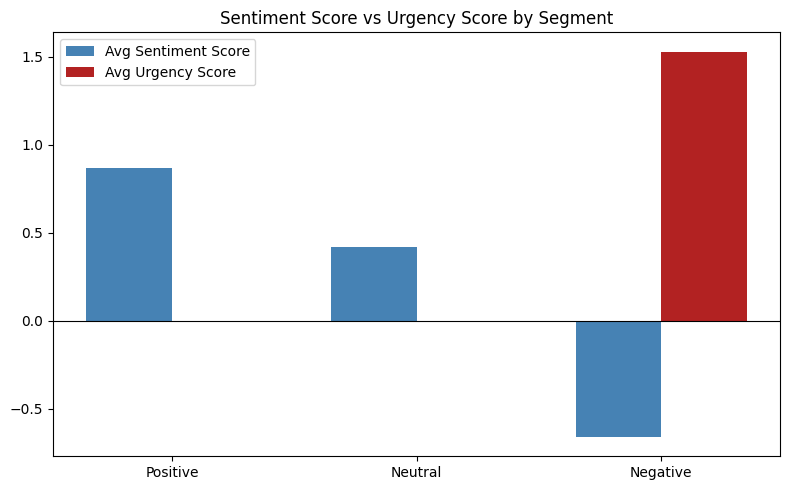

In [ ]:
# Building a grouped bar chart comparing sentiment score and urgency score across segments
segments = ['Positive', 'Neutral', 'Negative']
sentiment_values = [0.87, 0.42, -0.66]
urgency_values = [0.00, 0.00, 1.53]

x = np.arange(len(segments))   # positions for each segment
width = 0.35                    # width of each bar

fig, ax = plt.subplots(figsize=(8, 5))
bar1 = ax.bar(x - width/2, sentiment_values, width, label='Avg Sentiment Score', color='steelblue')
bar2 = ax.bar(x + width/2, urgency_values, width, label='Avg Urgency Score', color='firebrick')

ax.set_xticks(x)
ax.set_xticklabels(segments)
ax.set_title('Sentiment Score vs Urgency Score by Segment')
ax.axhline(0, color='black', linewidth=0.8)   # a line at zero, since sentiment can be negative
ax.legend()

plt.tight_layout()
plt.show()

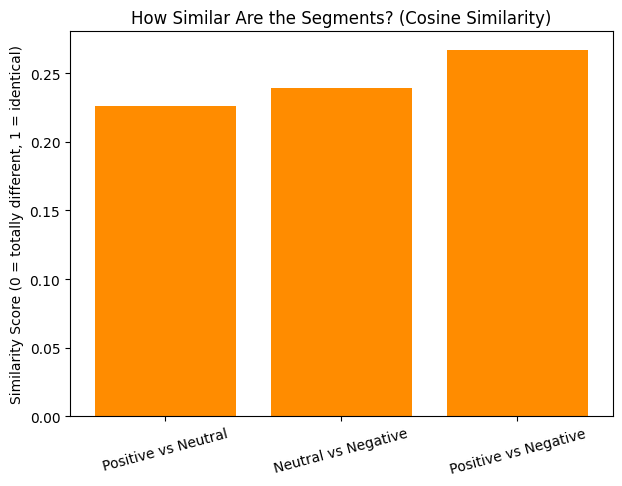

In [ ]:
# Building a bar chart of the cosine similarity scores between segments
pairs = ['Positive vs Neutral', 'Neutral vs Negative', 'Positive vs Negative']
similarity_values = [0.226, 0.239, 0.267]

plt.figure(figsize=(7, 5))
plt.bar(pairs, similarity_values, color='darkorange')
plt.title('How Similar Are the Segments? (Cosine Similarity)')
plt.ylabel('Similarity Score (0 = totally different, 1 = identical)')
plt.xticks(rotation=15)
plt.show()

## Milestone 2 — Conceptual Task 4: How Segmentation Supports Decision-Making

Treating all 3,000 reviews as one undifferentiated pool would force the business into a single, generic response strategy — which my data shows would be wrong for at least two of the three segments. Segmentation converts a single large, ambiguous dataset into three groups with distinct, measurable characteristics (sentiment score, urgency score, word count, and vocabulary), each of which implies a different action:

- **Positive segment** (avg sentiment 0.87, urgency 0.00): a low-effort opportunity for advocacy — request reviews/testimonials, no support burden.
- **Neutral segment** (avg sentiment 0.42, urgency 0.00, but its own distinct "lukewarm" vocabulary): an under-served opportunity segment — customers who are not complaining but are not enthusiastic either. Proactive outreach here (e.g. a short survey) can convert acceptable experiences into loyal ones at relatively low cost.
- **Negative segment** (avg sentiment -0.66, urgency 1.53): a resourcing and escalation priority — this segment alone should determine support SLA and staffing, since it combines strong negative sentiment with a measurable urgency signal.

Without segmentation, a single "average sentiment across all reviews" metric would look moderately positive (roughly 0.21 blended) and mask both the churn risk in the Negative segment and the missed opportunity in the Neutral segment. Segmentation therefore directly supports resource allocation (where support time is spent), product prioritization (which complaints justify a fix), and marketing decisions (who to ask for a testimonial) — each segment maps to a different team and a different action, which a single blended score cannot provide.

## Milestone 2 — Conceptual Task 5: Potential Bias in AI-Driven Segmentation

Several sources of bias are worth flagging in the segmentation approach used here:

- **Rating-based segmentation bias:** I segmented primarily by star rating (4-5 / 3 / 1-2), but Milestone 1 showed this doesn't perfectly track actual sentiment — 78% of "Neutral" (3-star) reviews are text-Positive. Anyone using the rating_bucket alone (without the text-sentiment cross-check) would misclassify a large share of genuinely satisfied customers as "needs improvement," and could equally miss a smaller group of genuinely unhappy 3-star reviewers.
- **Keyword-selection bias in urgency scoring:** My urgency score was built from a manually chosen list of 10 words. This list was derived by first looking at what showed up in negative reviews — meaning it was somewhat "fit" to this dataset. On real-world data, this could cause the model to miss urgent issues phrased with different vocabulary (e.g., a customer writing "unsafe" or "fire hazard" wouldn't register as urgent under our current keyword list) — a form of selection bias baked into the feature design itself.
- **Sentiment-tool bias:** VADER is a rule-based, lexicon-driven tool tuned mostly for general English text; it can misread sarcasm, industry-specific language, or culturally-specific phrasing, systematically under- or over-scoring certain groups of customers whose writing style differs from the tool's training assumptions.
- **Synthetic/templated data bias:** As flagged throughout this project, the dataset shows templated review structures. Patterns I've found (e.g., "quality" appearing everywhere, urgency = 0 outside Negative) may be artifacts of how this dataset was generated rather than genuine properties of real customer language, and would need re-validation on organic review data before being trusted in production.

**Business implication:** AI-driven segmentation should be treated as a decision-support tool, not an autonomous decision-maker — outputs should be periodically audited against human judgment (especially for the Neutral segment, where misclassification risk is highest), and urgency/sentiment keyword lists should be revisited regularly as new complaint language emerges, rather than treated as fixed.

# -------------------- END OF MILESTONE 2 --------------------

## MILESTONE 3: GenAI-Powered Review Assistant (Deployment Phase)

### Task 1 — Package the Trained NLP and ML Pipeline

In [ ]:
# This class bundles everything I built in Milestones 1 & 2 into ONE reusable tool.

class ReviewAnalyzer:

    def __init__(self):
        # These are the same word lists I used before
        self.urgency_words = ['refund', 'immediately', 'want', 'defective', 'broken',
                               'stopped', 'unusable', 'urgent', 'asap', 'terrible']

        # A simple theme dictionary: theme name -> list of keywords that signal it
        self.themes = {
            'Product Defect': ['defective', 'broken', 'stopped', 'working', 'unusable'],
            'Refund Request': ['refund', 'money', 'want'],
            'Quality Complaint': ['worst', 'terrible', 'awful', 'cheap', 'materials'],
            'Praise': ['amazing', 'perfectly', 'exceeded', 'great', 'best', 'excellent']
        }

    # Step 1: Text preprocessing (same as Milestone 1)
    def clean_text(self, text):
        if not isinstance(text, str):
            return ""
        text = text.lower()
        text = re.sub(r'[^a-z\s]', ' ', text)
        text = re.sub(r'\s+', ' ', text).strip()
        tokens = text.split()
        tokens = [word for word in tokens if word not in stop_words and len(word) > 1]
        return " ".join(tokens)

    # Step 2: Sentiment model (same VADER logic as Milestone 1)
    def get_sentiment(self, raw_text):
        scores = sia.polarity_scores(raw_text)
        compound, pos, neg = scores['compound'], scores['pos'], scores['neg']
        if pos > 0.1 and neg > 0.1:
            return "Mixed", compound
        elif compound >= 0.05:
            return "Positive", compound
        elif compound <= -0.05:
            return "Negative", compound
        else:
            return "Neutral", compound

    # Step 3: Urgency score (same logic as Milestone 2)
    def get_urgency(self, clean_text):
        words_in_review = clean_text.split()
        count = 0
        for word in words_in_review:
            if word in self.urgency_words:
                count = count + 1
        return count

    # Step 4: Theme extraction logic (new — finds which themes apply to this review)
    def get_themes(self, clean_text):
        words_in_review = clean_text.split()
        found_themes = []
        for theme_name, keywords in self.themes.items():
            for word in words_in_review:
                if word in keywords:
                    found_themes.append(theme_name)
                    break   # only add each theme once, even if multiple keywords match
        return found_themes

    # This ties all 4 steps together into ONE function — this is what my app will call
    def analyze(self, title, text):
        full_text = title + ". " + text
        cleaned = self.clean_text(full_text)
        sentiment_label, sentiment_score = self.get_sentiment(full_text)
        urgency = self.get_urgency(cleaned)
        themes = self.get_themes(cleaned)

        return {
            "sentiment": sentiment_label,
            "sentiment_score": round(sentiment_score, 3),
            "urgency_score": urgency,
            "themes": themes
        }

# Creating one instance of my package
analyzer = ReviewAnalyzer()

print("Package created!")

Package created!


In [ ]:
# Testing it on review #4 from my original dataset (the defective webcam one)
test_title = df['review_title'].iloc[4]
test_text = df['review_text'].iloc[4]

print("Title:", test_title)
print("Text:", test_text)
print()
print("Result:", analyzer.analyze(test_title, test_text))

Title: Not as described
Text: This Webcam HD is defective and unusable. Cheapest materials, worst functionality. I want a full refund! Very angry customer! International sell several real federal only.

Result: {'sentiment': 'Negative', 'sentiment_score': -0.897, 'urgency_score': 4, 'themes': ['Product Defect', 'Refund Request', 'Quality Complaint']}


In [ ]:
# Saving the packaged pipeline to disk using pickle, exactly as shown in the project guidelines
import pickle

with open("sentiment_pipeline.pkl", "wb") as f:
    pickle.dump(analyzer, f)

print("Pipeline saved as sentiment_pipeline.pkl")

Pipeline saved as sentiment_pipeline.pkl


In [ ]:
# Loading the saved pipeline back to confirm it works for inference
with open("sentiment_pipeline.pkl", "rb") as f:
    loaded_analyzer = pickle.load(f)

# Testing that the reloaded version works the same way
print(loaded_analyzer.analyze(test_title, test_text))

{'sentiment': 'Negative', 'sentiment_score': -0.897, 'urgency_score': 4, 'themes': ['Product Defect', 'Refund Request', 'Quality Complaint']}


### Task 2 — Build the Gradio Application

In [ ]:
# This function takes the review + my analysis, and asks Gemini to write a polite draft reply.
# I'm keeping a human in the loop here — this is a DRAFT for a support agent to review, not an auto-send.

def generate_draft_response(title, text, analysis_result):
    prompt = f"""
    You are a customer support assistant. Write a short, polite, professional draft response
    to this customer review. Do NOT make promises about refunds or replacements yourself —
    just acknowledge the issue and reassure the customer a team member will help.

    Review title: {title}
    Review text: {text}

    Our analysis found:
    - Sentiment: {analysis_result['sentiment']}
    - Urgency score: {analysis_result['urgency_score']}
    - Themes detected: {', '.join(analysis_result['themes']) if analysis_result['themes'] else 'None'}

    Write a 2-3 sentence draft response a support agent could review and send.
    """

    response = client.models.generate_content(
        model="gemini-2.5-flash",
        contents=prompt
    )

    return response.text

In [ ]:
# This is the single function that powers my whole app.
# Gradio calls this every time someone clicks "Submit."

def review_assistant(review_title, review_text):
    # Step 1: Run my packaged analyzer (sentiment, urgency, themes)
    analysis = analyzer.analyze(review_title, review_text)

    # Step 2: Format the themes as a simple readable string
    if len(analysis['themes']) > 0:
        themes_text = ", ".join(analysis['themes'])
    else:
        themes_text = "No specific theme detected"

    # Step 3: Ask Gemini to draft a response
    draft_reply = generate_draft_response(review_title, review_text, analysis)

    # Step 4: Return everything Gradio needs to display
    sentiment_display = f"{analysis['sentiment']} (score: {analysis['sentiment_score']})"
    urgency_display = f"{analysis['urgency_score']} / 10"

    return sentiment_display, urgency_display, themes_text, draft_reply

In [ ]:
# Building the Gradio app: takes a review title/text and returns sentiment, urgency, themes, and a draft response
import gradio as gr

with gr.Blocks(title="GenAI Review Assistant") as demo:
    gr.Markdown("# GenAI-Powered Review Assistant")
    gr.Markdown("Enter a customer review below to get sentiment, urgency, themes, and a draft response.")
    gr.Markdown("**Note:** This tool assists support agents — draft responses should always be reviewed by a human before sending (Human-in-the-Loop).")

    with gr.Row():
        with gr.Column():
            title_input = gr.Textbox(label="Review Title", placeholder="e.g. Not as described")
            text_input = gr.Textbox(label="Review Text", lines=4, placeholder="Paste the full review here...")
            submit_btn = gr.Button("Analyze Review", variant="primary")

        with gr.Column():
            sentiment_output = gr.Textbox(label="Predicted Sentiment")
            urgency_output = gr.Textbox(label="Urgency Score")
            themes_output = gr.Textbox(label="Detected Themes")
            draft_output = gr.Textbox(label="GenAI Draft Response (for agent review)", lines=4)

    submit_btn.click(
        fn=review_assistant,
        inputs=[title_input, text_input],
        outputs=[sentiment_output, urgency_output, themes_output, draft_output]
    )

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ac77951d892c622c15.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### Task 3 — Optional Database Integration

In [ ]:
import sqlite3

# Reconnecting to my database file (same one from Milestone 1)
connection = sqlite3.connect("reviews.db")
cursor = connection.cursor()

# Pulling ONE random review, including its rowid so I can reference it later
cursor.execute("SELECT rowid, rating, review_title, review_text FROM customer_reviews ORDER BY RANDOM() LIMIT 1;")
sample_row = cursor.fetchone()

sample_rowid = sample_row[0]
sample_rating = sample_row[1]
sample_title = sample_row[2]
sample_text = sample_row[3]

print("Pulled review #", sample_rowid)
print("Rating:", sample_rating)
print("Title:", sample_title)
print("Text:", sample_text)

Pulled review # 968
Rating: 4
Title: Absolutely fantastic!
Text: This Desk Lamp is exactly what I needed. Great quality, fast shipping, and the build quality works perfectly. Very satisfied customer here! Participant check several much single morning a.


In [ ]:
# Using the same analyzer package from Task 1
analysis_result = analyzer.analyze(sample_title, sample_text)

# Using the same draft response function from Task 2
draft_response = generate_draft_response(sample_title, sample_text, analysis_result)

print("Sentiment:", analysis_result['sentiment'])
print("Urgency score:", analysis_result['urgency_score'])
print("Themes:", analysis_result['themes'])
print()
print("Draft response:")
print(draft_response)

Sentiment: Positive
Urgency score: 0
Themes: ['Praise']

Draft response:
Thank you for your fantastic review! We're delighted to hear that our Desk Lamp is exactly what you needed and that you're so satisfied with your purchase. Our team is always here to assist should you have any questions or require further assistance.


In [ ]:
# Creating a new table (only if it doesn't already exist) to hold my AI-generated results.
# Keeping this separate from the original customer_reviews table so I never modify the raw data.

cursor.execute("""
CREATE TABLE IF NOT EXISTS generated_responses (
    review_rowid INTEGER,
    sentiment TEXT,
    urgency_score INTEGER,
    themes TEXT,
    draft_response TEXT
);
""")

# Turning the themes list into a simple comma-separated string for storage
themes_as_text = ", ".join(analysis_result['themes'])

# Inserting my results as one new row
cursor.execute("""
INSERT INTO generated_responses (review_rowid, sentiment, urgency_score, themes, draft_response)
VALUES (?, ?, ?, ?, ?);
""", (sample_rowid, analysis_result['sentiment'], analysis_result['urgency_score'], themes_as_text, draft_response))

# Saving (committing) the changes to the database file
connection.commit()

print("Saved to database!")

Saved to database!


In [ ]:
# Reading back the saved row to confirm everything was stored correctly
cursor.execute("SELECT * FROM generated_responses;")
saved_rows = cursor.fetchall()

for row in saved_rows:
    print(row)

connection.close()

(968, 'Positive', 0, 'Praise', "Thank you for your fantastic review! We're delighted to hear that our Desk Lamp is exactly what you needed and that you're so satisfied with your purchase. Our team is always here to assist should you have any questions or require further assistance.")


### Task 4 — Generate App Snapshots

In [ ]:
# Grabbing a real 3-star review from my dataset to test in the Gradio app
neutral_example = df[df['rating_bucket'] == 'Neutral'].iloc[0]
print("Title:", neutral_example['review_title'])
print("Text:", neutral_example['review_text'])

Title: Decent
Text: It's a decent Smart Watch for the money. Nothing to complain about but also nothing to rave about either.


# -------------------- END OF MILESTONE 3 --------------------